In [7]:
import gc, json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from tqdm.auto import tqdm

import traceback

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel
from cycler import cycler

LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]
plt.rcParams["axes.prop_cycle"] = cycler(color=LANCET_PALETTE)


def make_record(row):
    attr_code = row["attribute"]
    group_val = row["group"]
    personas = {attr_code: group_val}
    return {
        "qid": row["qid"],
        "type": row["type"],
        "question": row["question"],
        "option_texts": row["option_texts"],
        "country": row["c_alphan"],
        "personas": personas,
        "attribute": attr_code,
        "persona": f"{PERSONA_NAMES[attr_code]}={group_val}",
        "human_dist": row["human_dist"],
    }


def consensus(probs):
    num_options = len(probs)
    if num_options <= 1:
        raise ValueError(f"consensus requires at least 2 options, got {num_options}")
    scale_points = np.arange(1, num_options + 1, dtype=float)
    mean_score = float(np.dot(scale_points, probs))
    return float(
        1.0 + np.sum(probs * np.log2(1.0 - np.abs(scale_points - mean_score) / (num_options - 1) + 1e-12))
    )
def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1

def build_persona_dataset(df, attr_sets=None):
    if attr_sets is None:
        sub = df
    else:
        sets = [[attr_sets]] if isinstance(attr_sets, str) else attr_sets
        allowed = {cols[0] if isinstance(cols, (list, tuple)) else cols for cols in sets}
        sub = df[df["attribute"].isin(allowed)]
    return [make_record(row) for row in sub.to_dict("records")]


def make_view(rec):
    qid = rec["qid"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]

    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in rec["personas"].items())

    if q_type == "score":
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    elif q_type == "choice":
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")

    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": rec["question"],
                "criteria": criteria,
                "target": target,
            }
        },
    }
def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    if hasattr(sys, "last_value"):
        sys.last_value = None
    if hasattr(sys, "last_type"):
        sys.last_type = None
    if hasattr(sys, "last_exc"):
        sys.last_exc = None
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


In [8]:
PERSONA_NAMES = {
    "c_alphan": "Country",
    "CREGION": "Region",
    "EDUCATION": "Education",
    "INCOME": "Income",
    "POLIDEOLOGY": "Political ideology",
    "POLPARTY": "Political party",
    "RACE": "Race",
    "RELIG": "Religion",
    "SEX": "Sex",
}
NAMES_PERSONA = {v: k for k,v in PERSONA_NAMES.items()}

subpop_path = Path("data/subpop/subpop_eval.jsonl")
raw_rows = []
with subpop_path.open() as f:
    for line in f:
        block = json.loads(line)
        prefix, attr_code, group_val = block["group"].split("/", 2)
        if prefix != "SUBPOP":
            raise ValueError(f"Unexpected group prefix in {block['group']!r}")
        persona_label = PERSONA_NAMES[attr_code]
        if block["persona"][persona_label] != group_val:
            raise ValueError(f"{block['group']}: persona mismatch {block['persona']}")
        country = block["persona"]["Country"]

        for qid, q in block["questions"].items():
            q_type = q["type"]
            if q_type == "score":
                option_texts = list(q["criteria"])
                human_dist = np.array([q["target"][str(i)] for i in range(len(option_texts))], dtype=np.float64)
            elif q_type == "choice":
                option_texts = list(q["criteria"].keys())
                human_dist = np.array([q["target"][opt] for opt in option_texts], dtype=np.float64)
            else:
                raise ValueError(f"{qid}: unexpected question type {q_type!r}")

            raw_rows.append({
                "qid": qid,
                "type": q_type,
                "question": q["instructions"],
                "option_texts": option_texts,
                "c_alphan": country,
                "attribute": attr_code,
                "group": group_val,
                "human_dist": human_dist,
            })

subpop_df = pd.DataFrame(raw_rows)
print(f"subpop_eval: {len(subpop_df):>7,} records across {subpop_df['qid'].nunique():>3} questions and {subpop_df['group'].nunique():>2} subpopulations")

subpop_df.head(2)

subpop_eval:   2,926 records across 133 questions and 22 subpopulations


,qid,type,question,option_texts,c_alphan,attribute,group,human_dist
0,natspac,score,We are faced with many problems in this countr...,"[Too little, About right, Too much]",United States,CREGION,Northeast,"[0.3076, 0.4115, 0.2809]"
1,natenvir,score,We are faced with many problems in this countr...,"[Too little, About right, Too much]",United States,CREGION,Northeast,"[0.699, 0.1868, 0.1142]"


In [9]:
subpop_df[subpop_df['attribute']=='RACE']['group'].value_counts()

group
Black       133
White       133
Asian       133
Hispanic    133
Name: count, dtype: int64

In [10]:
single_persona_attrs = [c for c in PERSONA_NAMES.keys() if c != "c_alphan"]
subpop_records = build_persona_dataset(subpop_df, attr_sets=single_persona_attrs)
print(f"SubPOP eval records: {len(subpop_records):,}")
pd.DataFrame(subpop_records)[["qid", "type", "attribute", "persona", "human_dist"]].head(5)


SubPOP eval records: 2,926


,qid,type,attribute,persona,human_dist
0,natspac,score,CREGION,Region=Northeast,"[0.3076, 0.4115, 0.2809]"
1,natenvir,score,CREGION,Region=Northeast,"[0.699, 0.1868, 0.1142]"
2,natheal,score,CREGION,Region=Northeast,"[0.7429, 0.2225, 0.0346]"
3,natcity,score,CREGION,Region=Northeast,"[0.5976, 0.2711, 0.1312]"
4,natdrug,score,CREGION,Region=Northeast,"[0.092, 0.1868, 0.7212]"


In [11]:
print(list(NAMES_PERSONA.keys()))

attr = "Political party"
target_attr = NAMES_PERSONA[attr]
attr_label = PERSONA_NAMES[target_attr]
attr_dataset = build_persona_dataset(
    subpop_df, attr_sets=[[target_attr]],
)
attr_levels = list(dict.fromkeys(s["personas"][target_attr] for s in attr_dataset))
print(f"{target_attr} ({attr_label}) levels: {attr_levels}")


['Country', 'Region', 'Education', 'Income', 'Political ideology', 'Political party', 'Race', 'Religion', 'Sex']
POLPARTY (Political party) levels: ['Democrat', 'Republican']


In [12]:
records_by_qid = {}
for s in attr_dataset:
    records_by_qid.setdefault(s["qid"], {})[s["personas"][target_attr]] = s

mixed_rows = []
for qid, grp in records_by_qid.items():
    if set(grp.keys()) != set(attr_levels):
        raise ValueError(f"{qid}: expected {set(attr_levels)}, got {set(grp.keys())}")
    first_rec = grp[attr_levels[0]]
    if first_rec["type"] != "score" or len(first_rec["option_texts"]) != 5:
        continue
    scale_points = np.arange(1, len(first_rec["option_texts"]) + 1, dtype=float)
    row_dict = {"qid": qid, "question": first_rec["question"]}
    means = []
    for lvl in attr_levels:
        dist = grp[lvl]["human_dist"]
        lvl_mean = float(np.dot(scale_points, dist))
        means.append(lvl_mean)
        row_dict[f"mean_{lvl}"] = round(lvl_mean, 3)
        row_dict[f"cns_{lvl}"] = round(consensus(dist), 3)
    row_dict["mean_diff"] = round(max(means) - min(means), 3)
    mixed_rows.append(row_dict)

mixed_df = pd.DataFrame(mixed_rows).sort_values("mean_diff", ascending=False).reset_index(drop=True)
mean_cols = [f"mean_{lvl}" for lvl in attr_levels]
cns_cols = [f"cns_{lvl}" for lvl in attr_levels]
display(mixed_df[["qid", *mean_cols, "mean_diff", *cns_cols, "question"]].head(12))


,qid,mean_Democrat,mean_Republican,mean_diff,cns_Democrat,cns_Republican,question
0,letin1a,2.691,3.936,1.245,0.616,0.600,Do you think the number of immigrants to Ameri...
1,marhomo,1.732,2.884,1.152,0.529,0.417,Do you agree or disagree? Homosexual couples s...
2,news,3.438,4.140,0.702,0.279,0.454,How often do you read the newspaper - every da...
3,fehire,2.050,2.708,0.658,0.654,0.550,"Please tell me whether you strongly agree, agr..."
4,granborn,2.401,1.786,0.616,0.198,0.426,Were all of your four grandparents born in thi...
5,parsol,2.225,2.245,0.020,0.574,0.600,Compared to your parents when they were the ag...
6,finrela,3.043,3.028,0.015,0.700,0.750,"Compared with American families in general, wo..."


In [13]:
top4_qids = list(mixed_df["qid"].head(4))
eval_records = []
for qid in top4_qids:
    for lvl in attr_levels:
        eval_records.append(records_by_qid[qid][lvl])

top4_qids

['letin1a', 'marhomo', 'news', 'fehire']

## kev-0.8b - default

In [14]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.enable_flash_sdp(False)
torch.backends.cuda.enable_mem_efficient_sdp(False)
model = KevPointerModel.load("jaredpalmer/kev-0.8b", device)
model.net.head.temperature = model.meta.temperature  # default Kev shipped temperature (2.35)
print(model.describe())
model.net.head.temperature

kev_08b_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
kev_08b_by_qid = {
    qid: {lvl: kev_08b_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}

kev_08b_default_temp = float(model.meta.temperature)
model.net.head.temperature = 1.0
kev_08b_t1_preds = predict_probs(model, eval_records, show_progress=True)
model.net.head.temperature = kev_08b_default_temp
kev_08b_t1_by_qid = {
    qid: {lvl: kev_08b_t1_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'loaded', 'trainable_params': 524800}


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## Kev 0.8 - Fine-tuned

In [15]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()

ft_08b_ckpt = "runs/kev-0.8b-stage4-mix/best"
model = KevPointerModel.load(ft_08b_ckpt, device)
model.net.head.temperature = 1.0
print(model.describe())
print("temperature:", model.net.head.temperature)

ft_08b_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
ft_08b_by_qid = {
    qid: {lvl: ft_08b_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'loaded', 'trainable_params': 524800}
temperature: 1.0


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## kev-4b - default

In [16]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.enable_flash_sdp(False)
torch.backends.cuda.enable_mem_efficient_sdp(False)
model = KevPointerModel.load("jaredpalmer/kev-4b", device)
model.net.head.temperature = model.meta.temperature  # default Kev shipped temperature (2.35)
print(model.describe())
model.net.head.temperature

kev_4b_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
kev_4b_by_qid = {
    qid: {lvl: kev_4b_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}
model.net.head.temperature

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-4B-Base', 'mode': 'loaded', 'trainable_params': 1311232}


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

2.406050072164233

predict:   0%|          | 0/1 [00:00<?, ?batch/s]

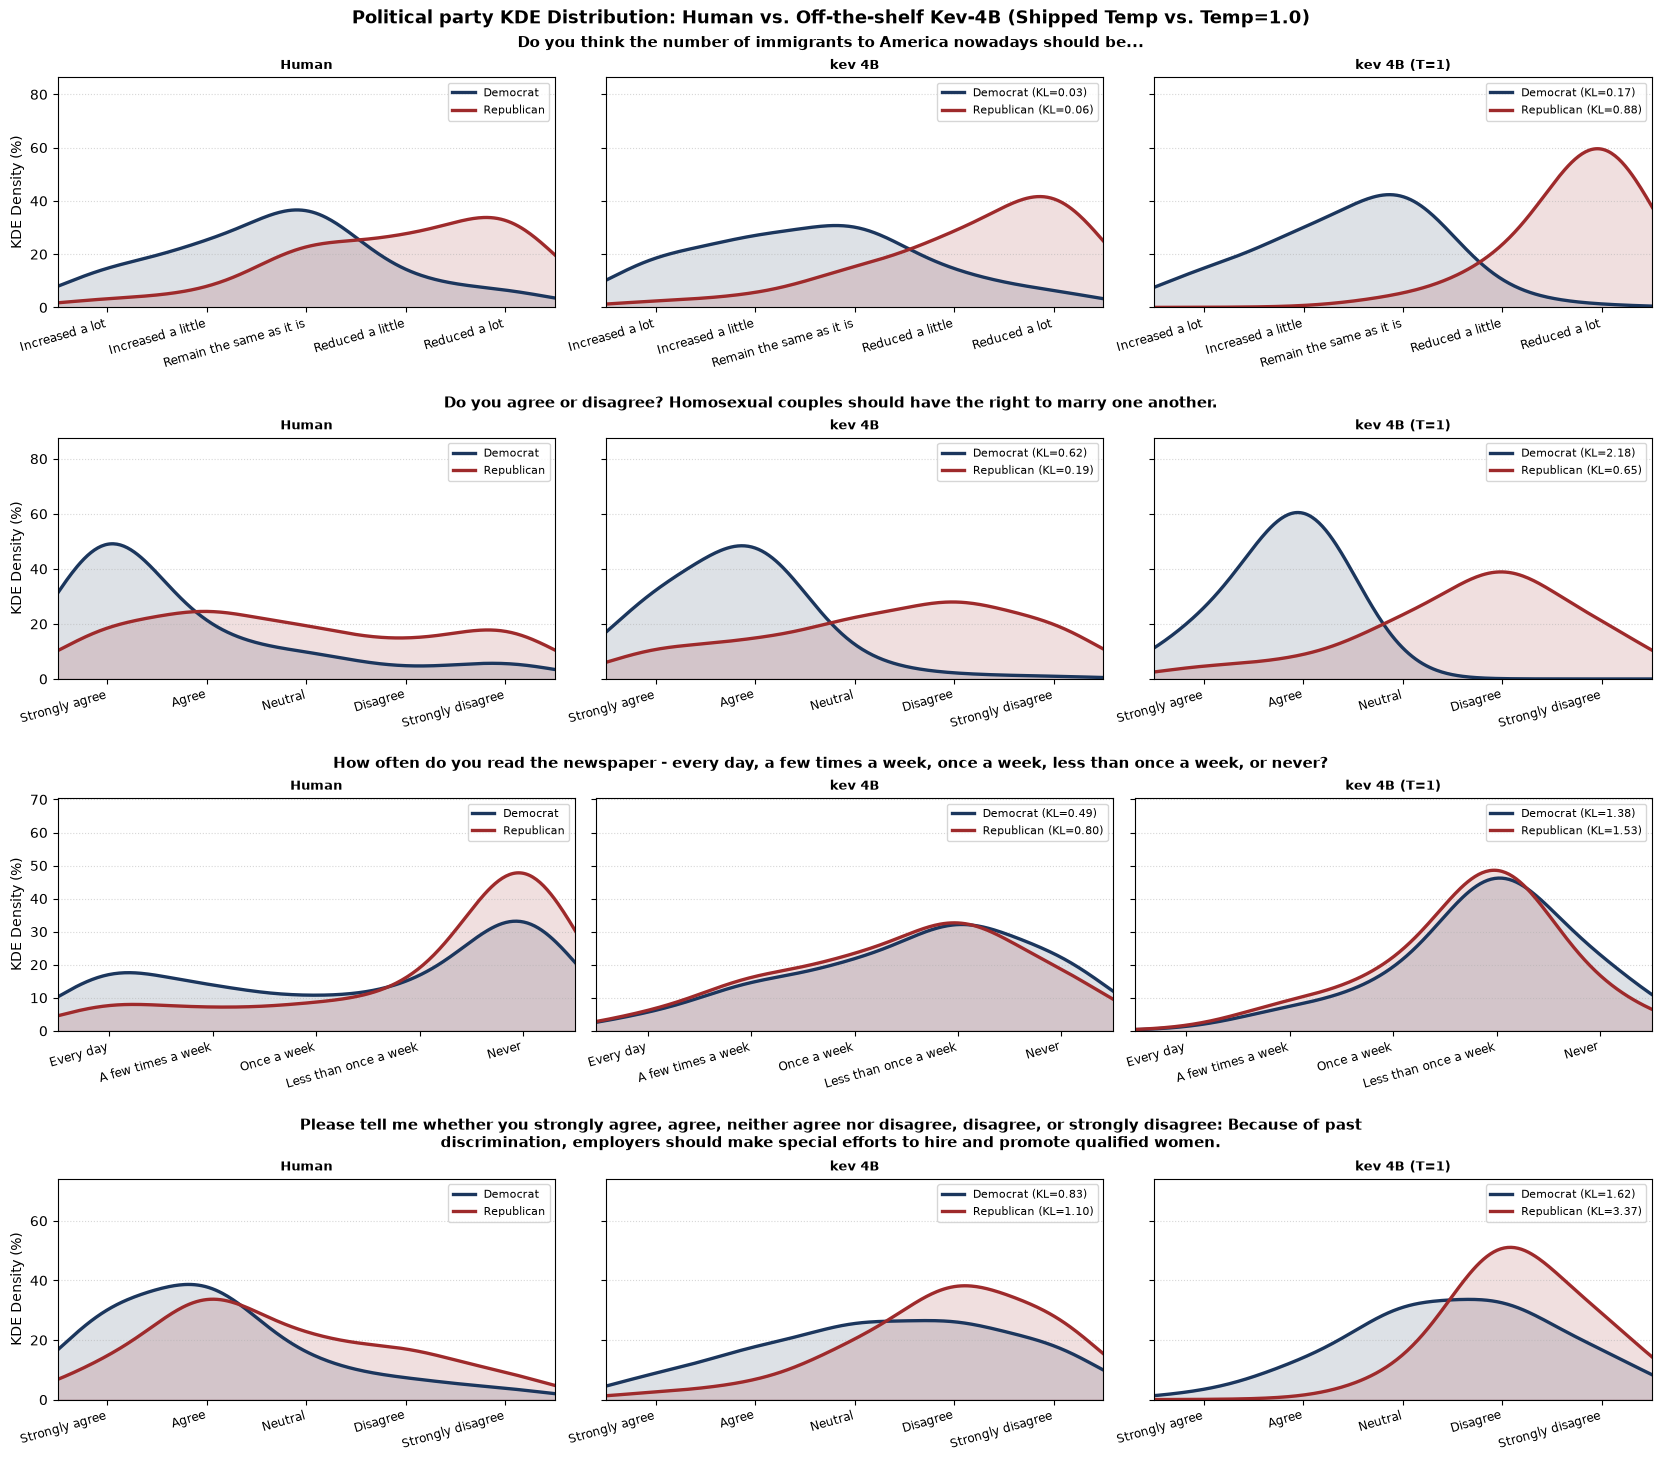

In [17]:
import textwrap

if model.meta.base != "Qwen/Qwen3.5-4B-Base" or model.meta.lora != 16:
    raise RuntimeError(f"Expected off-the-shelf jaredpalmer/kev-4b (lora=16), got base={model.meta.base!r}, lora={model.meta.lora}")

kev_4b_default_temp = float(model.meta.temperature)
model.net.head.temperature = 1.0
kev_4b_t1_preds = predict_probs(model, eval_records, show_progress=True)
model.net.head.temperature = kev_4b_default_temp

n_lvls = len(attr_levels)
kev_4b_t1_by_qid = {
    qid: {lvl: kev_4b_t1_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}

def discrete_kde_curve(probs, x_grid, bw=0.55):
    centers = np.arange(len(probs), dtype=float)
    kernels = np.exp(-0.5 * ((x_grid[:, None] - centers[None, :]) / bw) ** 2) / (bw * np.sqrt(2.0 * np.pi))
    return (kernels @ probs) * 100.0

temp_sources = [
    ("Human", lambda qid, lvl: records_by_qid[qid][lvl]["human_dist"]),
    ("kev 4B", lambda qid, lvl: kev_4b_by_qid[qid][lvl]),
    ("kev 4B (T=1)", lambda qid, lvl: kev_4b_t1_by_qid[qid][lvl]),
]

fig = plt.figure(figsize=(16.5, 14.5), constrained_layout=True)
subfigs = fig.subfigures(4, 1, hspace=0.05)

for row_idx, (subfig, (_, row)) in enumerate(zip(subfigs, mixed_df[["qid", "question"]].head(4).iterrows())):
    qid = row["qid"]
    opts = records_by_qid[qid][attr_levels[0]]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts), dtype=float)
    x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)
    wrapped_q = textwrap.fill(f"{row['question']}", width=140)
    subfig.suptitle(wrapped_q, fontsize=10.5, fontweight="bold")
    axes_row = subfig.subplots(1, len(temp_sources), sharey=True)

    for col_idx, (sample_name, get_dist) in enumerate(temp_sources):
        ax = axes_row[col_idx]
        top_y = 0.0

        for i, lvl in enumerate(attr_levels):
            dist = get_dist(qid, lvl)
            kde_vals = discrete_kde_curve(dist, x_grid)
            top_y = max(top_y, float(kde_vals.max()))

            if sample_name == "Human":
                lvl_label = f"{lvl}"
            else:
                h_dist = records_by_qid[qid][lvl]["human_dist"]
                lvl_kl, _ = dist_kl_w1(h_dist, dist)
                lvl_label = f"{lvl} (KL={lvl_kl:.2f})"

            color = LANCET_PALETTE[i % len(LANCET_PALETTE)]
            ax.fill_between(x_grid, kde_vals, color=color, alpha=0.15)
            ax.plot(x_grid, kde_vals, color=color, linewidth=2.4, linestyle="-", label=lvl_label)

        ax.set_ylim(0, max(ax.get_ylim()[1], top_y * 1.45))
        ax.set_xlim(-0.5, len(opts) - 0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(sample_name, fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("KDE Density (%)")

fig.suptitle(f"{attr_label} KDE Distribution: Human vs. Off-the-shelf Kev-4B (Shipped Temp vs. Temp=1.0)", fontsize=13, fontweight="bold")
plt.show()

## Kev 4B - Fine-tuned

In [18]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()

ft_4b_ckpt = "runs/kev-4b-stage2-k2/best"
model = KevPointerModel.load(ft_4b_ckpt, device)
model.net.head.temperature = 1.0
print(model.describe())
print("temperature:", model.net.head.temperature)

ft_4b_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
ft_4b_by_qid = {
    qid: {lvl: ft_4b_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-4B-Base', 'mode': 'loaded', 'trainable_params': 1311232}
temperature: 1.0


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## kev-9b - default

In [19]:
from kev.checkpoint import Checkpoint, LoadOptions

device = "cuda"
if "model" in globals():
    del model
free_gpu()
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.enable_flash_sdp(False)
torch.backends.cuda.enable_mem_efficient_sdp(False)

ck_9b = Checkpoint("jaredpalmer/kev-9b")
tok_9b, net_9b = ck_9b.load(device, LoadOptions(dtype=torch.bfloat16, temperature=1.0))
model = KevPointerModel(net_9b, tok_9b, ck_9b.meta, "loaded")
del ck_9b, tok_9b, net_9b

kev_9b_default_temp = float(model.meta.temperature)
model.net.head.temperature = kev_9b_default_temp  # default Kev-9B shipped temperature (2.19)
print(model.describe())
print("default temperature:", model.net.head.temperature)

kev_9b_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
kev_9b_by_qid = {
    qid: {lvl: kev_9b_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}

model.net.head.temperature = 1.0
kev_9b_t1_preds = predict_probs(model, eval_records, show_progress=True)
model.net.head.temperature = kev_9b_default_temp
kev_9b_t1_by_qid = {
    qid: {lvl: kev_9b_t1_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}
model.net.head.temperature

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-9B-Base', 'mode': 'loaded', 'trainable_params': 2097664}
default temperature: 2.193649959389252


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

predict:   0%|          | 0/1 [00:00<?, ?batch/s]

2.193649959389252

## Kev 9B - Fine-tuned

In [20]:
from kev.checkpoint import Checkpoint, LoadOptions

device = "cuda"
if "model" in globals():
    del model
free_gpu()

ft_9b_ckpt = "runs/kev-9b-stage2-k2/best"
ck_9b_ft = Checkpoint(ft_9b_ckpt)
tok_9b_ft, net_9b_ft = ck_9b_ft.load(device, LoadOptions(dtype=torch.bfloat16, temperature=1.0))
model = KevPointerModel(net_9b_ft, tok_9b_ft, ck_9b_ft.meta, "loaded")
del ck_9b_ft, tok_9b_ft, net_9b_ft

model.net.head.temperature = 1.0
print(model.describe())
print("temperature:", model.net.head.temperature)

ft_9b_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
ft_9b_by_qid = {
    qid: {lvl: ft_9b_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}
ft_9b_subpop_preds = predict_probs(model, subpop_records, batch_size=64, show_progress=True, autocast_bf16=True)
ft_9b_subpop_kl = float(np.mean([dist_kl_w1(r["human_dist"], p)[0] for r, p in zip(subpop_records, ft_9b_subpop_preds)]))
print(f"SubPOP KL (T=1.0): {ft_9b_subpop_kl:.4f}")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-9B-Base', 'mode': 'loaded', 'trainable_params': 2097664}
temperature: 1.0


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

predict:   0%|          | 0/46 [00:00<?, ?batch/s]

SubPOP KL (T=1.0): 0.1895


## Temp calibration for 9B model

In [23]:
import pickle
from kev.metrics import TEMPERATURE_FIT

ISSP_PERSONA_NAMES = {
    "c_alphan": "Country",
    "SEX": "Sex",
    "AGE": "Age",
    "EDULEVEL": "Education",
    "RELIGGRP": "Religion",
    "ATTEND": "Attendance of religious services",
    "PARTY_LR": "Political ideology",
    "VOTE_LE": "Voted in the last general election",
    "URBRURAL": "Place of living",
    "MARITAL": "Marital status",
    "MAINSTAT": "Main activity",
    "UNION": "Trade union membership",
    "US_PRTY": "Political party",
    "US_INC": "Income",
    "US_REG": "Region",
    "US_ETHN1": "Ancestry",
}

def make_issp_view(rec):
    qid = rec["qid"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]
    state_lines = [f"{ISSP_PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{ISSP_PERSONA_NAMES[c]}: {v}" for c, v in rec["personas"].items())
    if q_type == "score":
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    elif q_type == "choice":
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")
    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": rec["question"],
                "criteria": criteria,
                "target": target,
            }
        },
    }

valid_cache_files = sorted(Path(".cache").glob("valid_records_min100_*.pkl"))
if len(valid_cache_files) != 1:
    raise FileNotFoundError(f"Expected 1 valid_records cache file, found {valid_cache_files}")
with valid_cache_files[0].open("rb") as f:
    issp_valid_records = pickle.load(f)
print(f"Loaded {len(issp_valid_records):,} ISSP validation records from {valid_cache_files[0]}")

model.eval()
model.net.head.temperature = 1.0  # raw logits
val_raw_logits, val_targets = [], []
with torch.no_grad():
    for start in tqdm(range(0, len(issp_valid_records), 64), desc="cal_logits", unit="batch", leave=False):
        batch = issp_valid_records[start:start + 64]
        prepared = [model.prepare(make_issp_view(r)) for r in batch]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits_batch = model.forward([enc for enc, _ in prepared])
        for (_, targets), q_logits in zip(prepared, logits_batch):
            if len(q_logits) != 1 or len(targets) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(q_logits)}")
            val_raw_logits.append(q_logits[0].float().cpu().numpy())
            val_targets.append(targets[0]["target"].numpy())

# Kev's exact grid search (kev.metrics.fit_temperature with TEMPERATURE_FIT: 121-point log grid on 0.25..4)
candidates = np.exp(np.linspace(np.log(0.25), np.log(4.0), TEMPERATURE_FIT["points"]))
def nll_soft_at_temp(z, target, t):
    zt = (z - z.max()) / t
    log_probs = zt - np.log(np.exp(zt).sum())
    return float(-np.dot(target, log_probs))

cal_losses = [float(np.mean([nll_soft_at_temp(z, tgt, float(t)) for z, tgt in zip(val_raw_logits, val_targets)])) for t in candidates]
ft_9b_cal_temp = float(candidates[int(np.argmin(cal_losses))])
nll_soft_at_temp_t1 = float(np.mean([nll_soft_at_temp(z, tgt, 1.0) for z, tgt in zip(val_raw_logits, val_targets)]))
print(f"Calibrated temperature on ISSP valid: T={ft_9b_cal_temp:.4f} (min NLL={min(cal_losses):.4f} nats vs T=1.0 NLL={nll_soft_at_temp_t1:.4f} nats)")

model.net.head.temperature = ft_9b_cal_temp
ft_9b_tcal_preds = predict_probs(model, eval_records, show_progress=True)
ft_9b_tcal_by_qid = {
    qid: {lvl: ft_9b_tcal_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}
ft_9b_tcal_subpop_preds = predict_probs(model, subpop_records, batch_size=64, show_progress=True, autocast_bf16=True)
ft_9b_tcal_subpop_kl = float(np.mean([dist_kl_w1(r["human_dist"], p)[0] for r, p in zip(subpop_records, ft_9b_tcal_subpop_preds)]))
model.net.head.temperature = 1.0

eval_kl_t1 = float(np.mean([dist_kl_w1(r["human_dist"], p)[0] for r, p in zip(eval_records, ft_9b_preds)]))
eval_kl_tdef = float(np.mean([dist_kl_w1(r["human_dist"], p)[0] for r, p in zip(eval_records, ft_9b_tdef_preds)]))
eval_kl_tcal = float(np.mean([dist_kl_w1(r["human_dist"], p)[0] for r, p in zip(eval_records, ft_9b_tcal_preds)]))
print(f"Eval (top-4) KL — T=1.0: {eval_kl_t1:.4f} | T=default ({kev_9b_default_temp:.2f}): {eval_kl_tdef:.4f} | T=calibrated ({ft_9b_cal_temp:.2f}): {eval_kl_tcal:.4f}")
print(f"SubPOP (all) KL — T=1.0: {ft_9b_subpop_kl:.4f} | T=default ({kev_9b_default_temp:.2f}): {ft_9b_tdef_subpop_kl:.4f} | T=calibrated ({ft_9b_cal_temp:.2f}): {ft_9b_tcal_subpop_kl:.4f}")


Loaded 2,192 ISSP validation records from .cache/valid_records_min100_5245f35c.pkl


cal_logits:   0%|          | 0/35 [00:00<?, ?batch/s]

Calibrated temperature on ISSP valid: T=1.0968 (min NLL=1.3644 nats vs T=1.0 NLL=1.3656 nats)


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

predict:   0%|          | 0/46 [00:00<?, ?batch/s]

Eval (top-4) KL — T=1.0: 0.2415 | T=default (2.19): 0.2250 | T=calibrated (1.10): 0.2279
SubPOP (all) KL — T=1.0: 0.1895 | T=default (2.19): 0.2383 | T=calibrated (1.10): 0.1905


# Plots

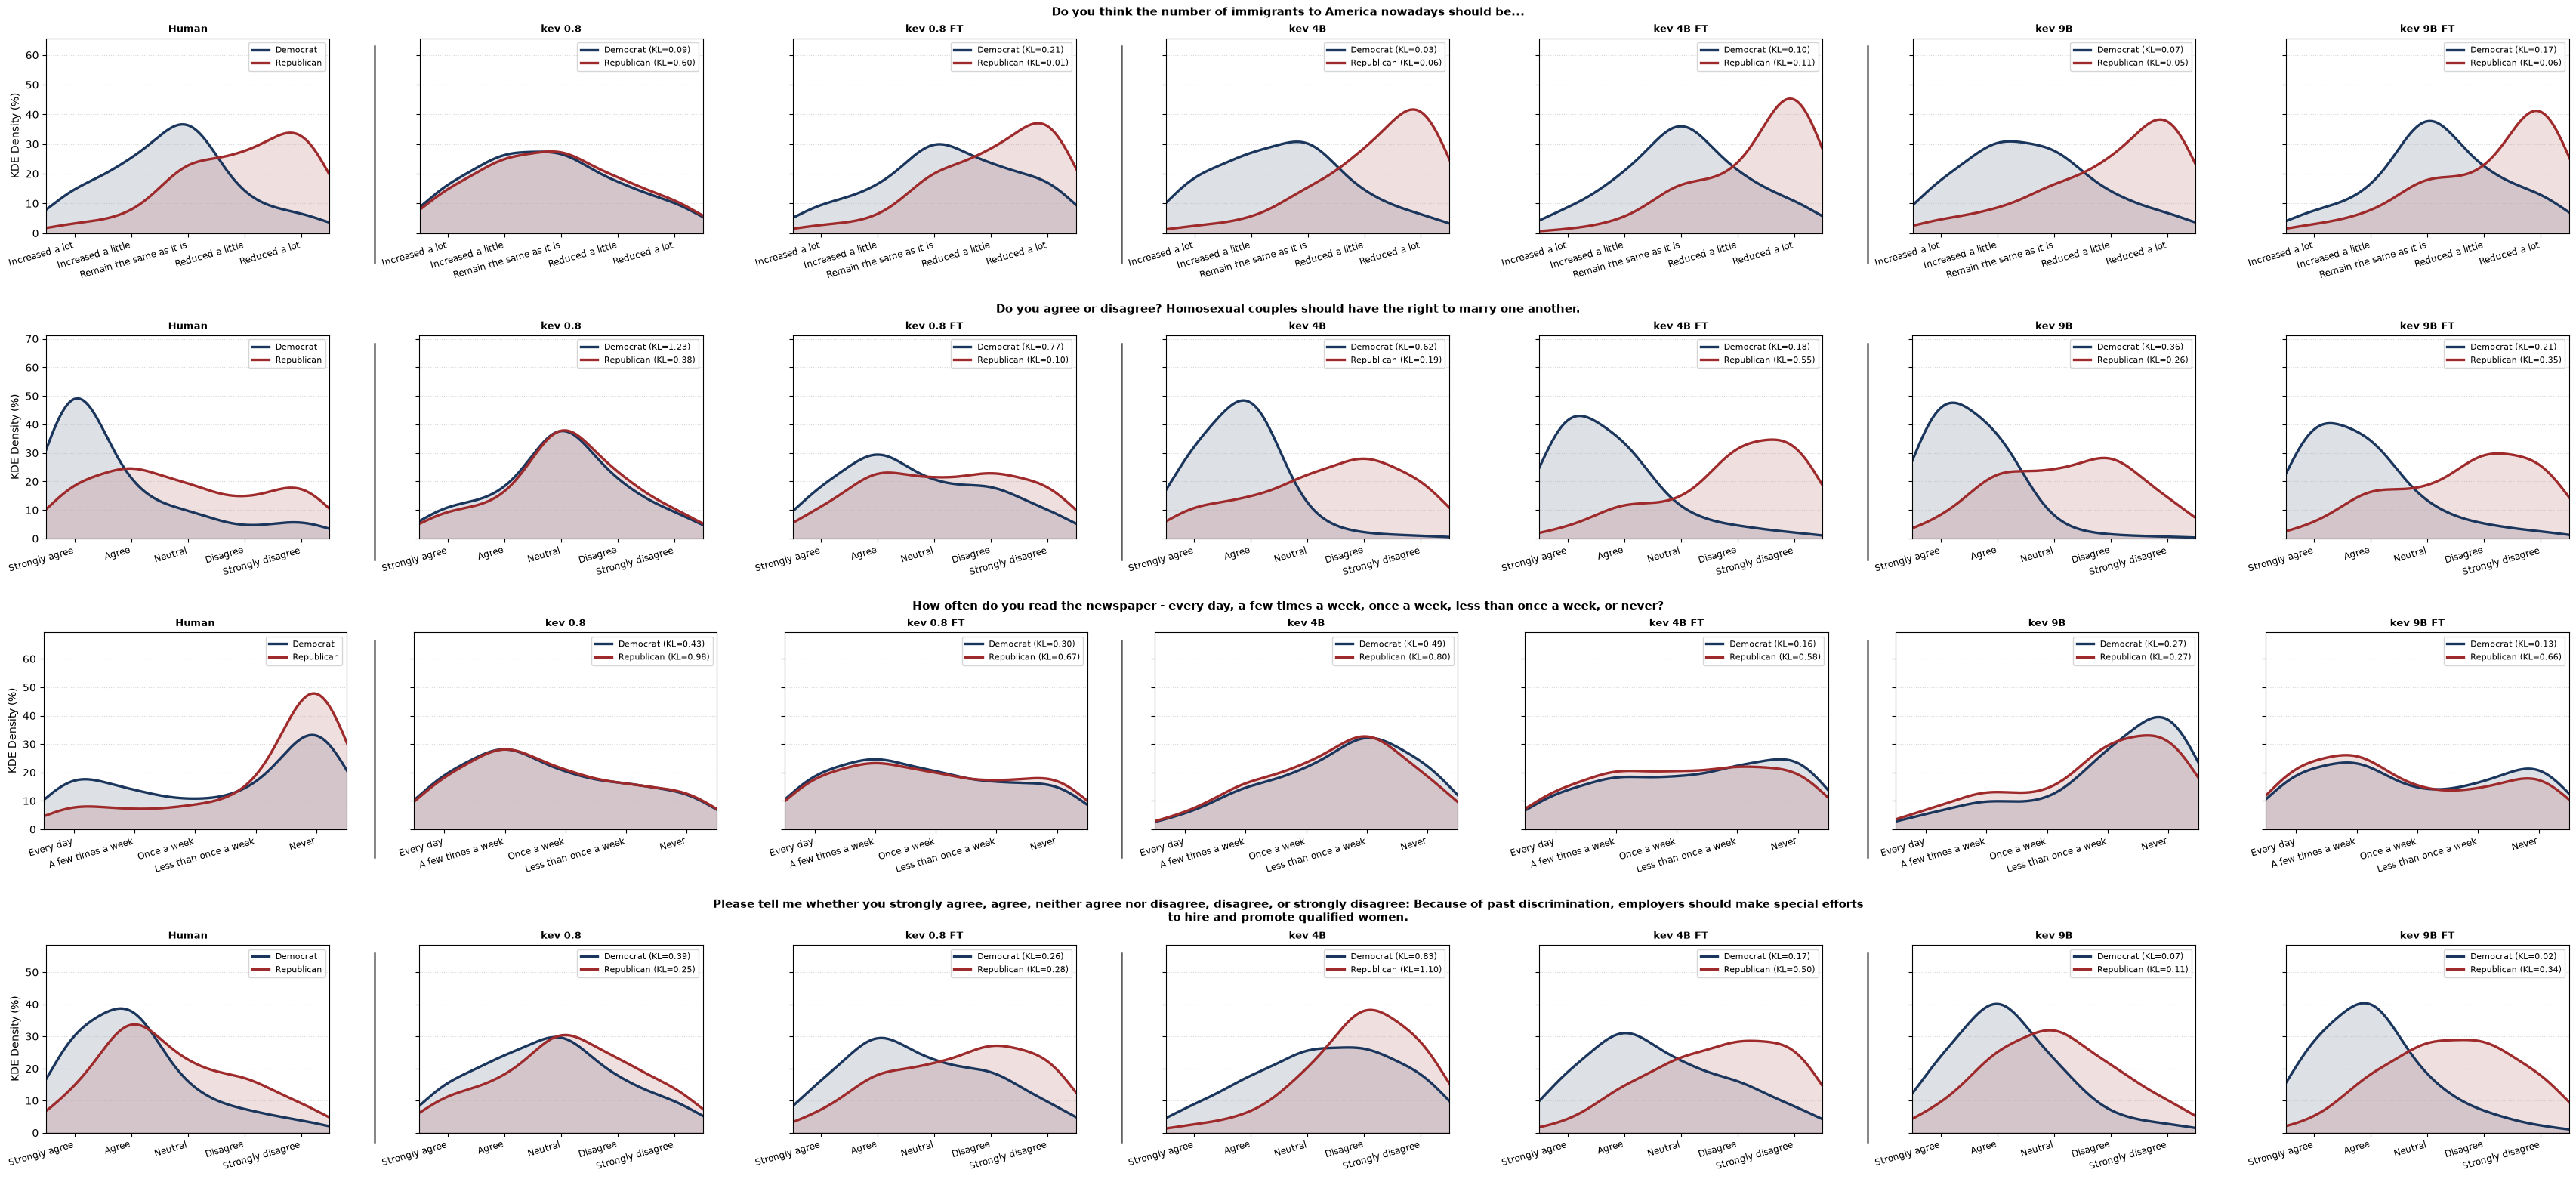

: 

In [ ]:
import textwrap

def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1

def discrete_kde_curve(probs, x_grid, bw=0.55):
    centers = np.arange(len(probs), dtype=float)
    kernels = np.exp(-0.5 * ((x_grid[:, None] - centers[None, :]) / bw) ** 2) / (bw * np.sqrt(2.0 * np.pi))
    return (kernels @ probs) * 100.0

sample_sources = [
    ("Human", lambda qid, lvl: records_by_qid[qid][lvl]["human_dist"]),
    ("kev 0.8", lambda qid, lvl: kev_08b_by_qid[qid][lvl]),
    # ("kev 0.8 (T=1)", lambda qid, lvl: kev_08b_t1_by_qid[qid][lvl]),
    ("kev 0.8 FT", lambda qid, lvl: ft_08b_by_qid[qid][lvl]),
    ("kev 4B", lambda qid, lvl: kev_4b_by_qid[qid][lvl]),
    # ("kev 4B (T=1)", lambda qid, lvl: kev_4b_t1_by_qid[qid][lvl]),
    ("kev 4B FT", lambda qid, lvl: ft_4b_by_qid[qid][lvl]),
    ("kev 9B", lambda qid, lvl: kev_9b_by_qid[qid][lvl]),
    # ("kev 9B (T=1)", lambda qid, lvl: kev_9b_t1_by_qid[qid][lvl]),
    ("kev 9B FT", lambda qid, lvl: ft_9b_by_qid[qid][lvl]),
]

from matplotlib.lines import Line2D

fig = plt.figure(figsize=(34.0, 15.5), constrained_layout=True)
subfigs = fig.subfigures(4, 1, hspace=0.06)
group_after_cols = {0, 2, 4}  # separate Human | Kev 0.8B | Kev 4B | Kev 9B

for row_idx, (subfig, (_, row)) in enumerate(zip(subfigs, mixed_df[["qid", "question"]].head(4).iterrows())):
    qid = row["qid"]
    opts = records_by_qid[qid][attr_levels[0]]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts), dtype=float)
    x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)

    wrapped_q = textwrap.fill(f"{row['question']}", width=180)
    subfig.suptitle(
        wrapped_q, fontsize=10.5, fontweight="bold", zorder=10,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 3.0},
    )
    axes_row = subfig.subplots(1, len(sample_sources), sharey=True, gridspec_kw={"wspace": 0.14})

    for col_idx, (sample_name, get_dist) in enumerate(sample_sources):
        ax = axes_row[col_idx]
        top_y = 0.0

        for i, lvl in enumerate(attr_levels):
            dist = get_dist(qid, lvl)
            kde_vals = discrete_kde_curve(dist, x_grid)
            top_y = max(top_y, float(kde_vals.max()))

            if sample_name == "Human":
                lvl_label = f"{lvl}"
            else:
                h_dist = records_by_qid[qid][lvl]["human_dist"]
                lvl_kl, _ = dist_kl_w1(h_dist, dist)
                lvl_label = f"{lvl} (KL={lvl_kl:.2f})"

            color = LANCET_PALETTE[i % len(LANCET_PALETTE)]
            ax.fill_between(x_grid, kde_vals, color=color, alpha=0.15)
            ax.plot(x_grid, kde_vals, color=color, linewidth=2.4, linestyle="-", label=lvl_label)

        ax.set_ylim(0, max(ax.get_ylim()[1], top_y * 1.45))
        ax.set_xlim(-0.5, len(opts) - 0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(sample_name, fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("KDE Density (%)")

# fig.suptitle(f"{attr_label} KDE Distribution Comparison by Sample (Human vs. Kev-0.8B vs. Kev-4B vs. Kev-9B)", fontsize=13.5, fontweight="bold")
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

# Draw disjoint vertical lines per question row with gaps between rows
inv_fig = fig.transFigure.inverted()
row_ax_bboxes = [[inv_fig.transform_bbox(ax.get_window_extent(renderer)) for ax in sf.axes] for sf in subfigs]
row_tight_bboxes = [[inv_fig.transform_bbox(ax.get_tightbbox(renderer)) for ax in sf.axes] for sf in subfigs]
top_bboxes = row_ax_bboxes[0]
title_bboxes = [inv_fig.transform_bbox(subfig._suptitle.get_window_extent(renderer)) for subfig in subfigs]

x_mids = [
    0.5 * (top_bboxes[col_idx].x1 + top_bboxes[col_idx + 1].x0)
    for col_idx in sorted(group_after_cols)
    if col_idx + 1 < len(top_bboxes)
]
y_mids = [
    0.5 * (min(b.y0 for b in row_tight_bboxes[r_idx]) + title_bboxes[r_idx + 1].y1)
    for r_idx in range(len(subfigs) - 1)
]

v_gap = 0.025  # symmetric padding shrunk from both top and bottom of each row segment
for r_idx in range(len(subfigs)):
    row_bot = (y_mids[r_idx]) if r_idx < len(y_mids) else min(b.y0 for b in row_tight_bboxes[-1])
    row_top = max(b.y1 for b in row_ax_bboxes[r_idx]) + 0.018
    seg_y0 = row_bot + v_gap
    seg_y1 = row_top - v_gap
    for x_mid in x_mids:
        fig.add_artist(
            Line2D([x_mid, x_mid], [seg_y0, seg_y1], transform=fig.transFigure,
                   color="#444444", linestyle="-", linewidth=1.8, alpha=0.85, zorder=1, clip_on=False)
        )

fig_dir = Path("../manuscript/figures")
attr_slug = attr_label.lower().replace(" ", "_")
fig.savefig(fig_dir / f"{attr_slug}_mixed_kde_by_sample_subpop.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# 2. Full SubPOP benchmark (all 2,926 subpopulation-question records) KL comparison
def eval_subpop_preds(records, preds_list):
    if len(records) != len(preds_list):
        raise ValueError(f"Expected {len(records)} predictions, got {len(preds_list)}")
    all_kls, score_kls, choice_kls, score_w1s = [], [], [], []
    for rec, m_dist in zip(records, preds_list):
        kl, w1 = dist_kl_w1(rec["human_dist"], m_dist)
        all_kls.append(kl)
        if rec["type"] == "score":
            score_kls.append(kl)
            score_w1s.append(w1)
        elif rec["type"] == "choice":
            choice_kls.append(kl)
        else:
            raise ValueError(f"Unexpected type {rec['type']!r}")
    return {
        "SubPOP All KL": float(np.mean(all_kls)),
        "SubPOP Score KL": float(np.mean(score_kls)),
        "SubPOP Choice KL": float(np.mean(choice_kls)),
        "SubPOP Score W1": float(np.mean(score_w1s)),
    }

from kev.checkpoint import Checkpoint, LoadOptions

uniform_preds_all = [np.full(len(r["human_dist"]), 1.0 / len(r["human_dist"])) for r in subpop_records]
if "subpop_summary" not in globals():
    subpop_summary = {}
subpop_summary["Uniform Baseline"] = eval_subpop_preds(subpop_records, uniform_preds_all)

if "ft_9b_subpop_preds" in globals():
    subpop_summary["kev 9B FT"] = eval_subpop_preds(subpop_records, ft_9b_subpop_preds)

model_specs = [
    ("kev 0.8", "jaredpalmer/kev-0.8b", None),
    ("kev 0.8 FT", "runs/kev-0.8b-stage4-mix/best", 1.0),
    ("kev 4B", "jaredpalmer/kev-4b", None),
    ("kev 4B FT", "runs/kev-4b-stage2-k2/best", 1.0),
    ("kev 9B", "jaredpalmer/kev-9b", None),
    ("kev 9B FT", "runs/kev-9b-stage2-k2/best", 1.0),
]

for label, ckpt_id, temp_override in model_specs:
    if label in subpop_summary:
        continue
    if "model" in globals():
        del model
    free_gpu()
    ck = Checkpoint(ckpt_id)
    tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0))
    model = KevPointerModel(net, tok, ck.meta, "loaded")
    del ck, tok, net
    model.net.head.temperature = float(model.meta.temperature) if temp_override is None else float(temp_override)
    print(f"{label}: temperature={model.net.head.temperature:.2f}")
    preds_all = predict_probs(model, subpop_records, batch_size=64, show_progress=True, autocast_bf16=True)
    subpop_summary[label] = eval_subpop_preds(subpop_records, preds_all)

ordered_cols = ["Uniform Baseline", *(label for label, _, _ in model_specs)]
subpop_summary_df = pd.DataFrame({col: subpop_summary[col] for col in ordered_cols})
display(subpop_summary_df.round(4))

,Uniform Baseline,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
SubPOP All KL,0.3758,0.4070,0.2930,0.3430,0.1985,0.3720,0.1895
SubPOP Score KL,0.3391,0.3486,0.3046,0.3080,0.2154,0.3146,0.1897
SubPOP Choice KL,0.4098,0.4611,0.2822,0.3755,0.1828,0.4252,0.1894
SubPOP Score W1,0.1771,0.1679,0.1591,0.1413,0.1216,0.1367,0.1097


## Best gains
For illustration of *how* finetuning helps reduce KL on Subpop, for the 0.8B model, 
1. find the cases with the most reduction in KL. 
2. create the comparative plot (human, baseline, FT) for that persona/question.
3. Do it for the top 5.